## 1. Business Problem

Logistics companies handle a large number of deliveries across different regions, vehicles, delivery partners, package types, and weather conditions.

Delivery delays can increase operational costs, reduce customer satisfaction, and affect overall supply chain efficiency.

A logistics analytics system can help organizations answer questions such as:

- Which deliveries are more likely to be delayed?
- Which delivery partners have higher delay rates?
- Does weather affect delivery performance?
- Which vehicle types perform better?
- How does delivery distance affect delays?
- Which regions have higher delivery risks?
- Which deliveries should be prioritized for operational attention?
- How can delivery costs and operational performance be monitored?

This project addresses these questions using data analytics and machine learning.

## 2. Project Objectives

The main objectives of this project are:

1. Clean and prepare the delivery dataset for analysis.
2. Perform exploratory data analysis to understand delivery patterns.
3. Identify factors associated with delivery delays.
4. Build machine learning models to predict delivery delays.
5. Compare different classification models using appropriate evaluation metrics.
6. Select and tune the best-performing model.
7. Generate delay probability and risk categories for deliveries.
8. Analyze delivery partner, vehicle, region, mode, and weather performance.
9. Analyze delivery cost and operational efficiency.
10. Generate actionable business insights for logistics decision-making.

## 3. Dataset Description

The dataset contains delivery-level information related to logistics operations.

### Key Features

| Feature | Description |
|---|---|
| Delivery_ID | Unique identifier for each delivery |
| Delivery_Partner | Delivery partner responsible for the delivery |
| Package_Type | Type/category of package |
| Vehicle_Type | Vehicle used for delivery |
| Delivery_Mode | Mode of delivery |
| Region | Delivery region |
| Weather_Condition | Weather condition during delivery |
| Distance_km | Delivery distance in kilometers |
| Package_weight_kg | Package weight in kilograms |
| Delayed | Indicates whether the delivery was delayed |
| Delivery_Status | Final delivery status |
| Delivery_rating | Customer/delivery rating |
| Delivery_cost | Cost associated with the delivery |

The dataset does not contain a proper date/time variable or GPS coordinates. Therefore, this project focuses on delivery delay prediction and operational logistics analysis rather than true time-series demand forecasting or GPS-based route optimization.

In [2]:
pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 4.4 MB/s eta 0:00:02
   ------- -------------------------------- 1.6/8.4 MB 4.1 MB/s eta 0:00:02
   ---------- ----------------------------- 2.1/8.4 MB 3.9 MB/s eta 0:00:02
   ------------- -------------------------- 2.9/8.4 MB 3.8 MB/s eta 0:00:02
   ----------------- ---------------------- 3.7/8.4 MB 3.7 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.4 MB 3.6 MB/s eta 0:00:02
   ---------------------- ----------------- 4.7/8.4 MB 3.6 MB/s eta 0:00:02
   -------------------------- ------------- 5.5/8.4 MB 3.3 MB/s eta 0:00:01
   -------------------------- ------------- 5.5/8.4 MB 3.3 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.4 MB 3.1 MB/s eta 0:00:01
   --------------------------------- ------ 7.1/8.4 MB 3.1 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 3.3 MB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 4. Import Required Libraries

The following Python libraries are used for data manipulation, visualization, machine learning, and model evaluation.

In [ ]:
import pandas as pd
import numpy as np
import os

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

## 5. Load the Dataset

The cleaned project workflow begins by loading the delivery dataset into a Pandas DataFrame.

The dataset is stored separately in the project's data directory to maintain a structured and reproducible project organization.

In [ ]:
df = pd.read_excel("C:/Users/Admin/Downloads/Delivery_Data_Kaggle.xlsx")

## 6. Initial Data Inspection

Before performing any analysis, the dataset is inspected to understand:

- Number of rows and columns
- Column names
- Data types and dataset information
- Basic statistical information
- Missing values
- Duplicate records

This step helps identify potential data-quality issues before analysis and modeling.

In [5]:
print(df.head())

   Delivery_ID Delivery_Partner      Package_Type Vehicle_Type Delivery_Mode  \
0            1        Delhivery  Automobile Parts         Bike      Same Day   
1            2       Xpressbees         Cosmetics       Ev Van       Express   
2            3        Shadowfax         Groceries        Truck       Two Day   
3            4              DHL       Electronics       Ev Van      Same Day   
4            5              DHL          Clothing          Van       Two Day   

    Region Weather_Condition  Distance_km  Package_weight_kg Delayed  \
0     West             Clear        297.0              46.96      No   
1  Central              Cold         89.6              47.39      No   
2     East             Rainy        273.5              26.89      No   
3     East              Cold        269.7              12.69      No   
4    North             Foggy        256.7              37.02      No   

  Delivery_Status  Delivery_rating  Delivery_cost  
0       Delivered                3

In [6]:
print(df.shape)

(25000, 13)


In [7]:
print(df.columns.tolist())

['Delivery_ID', 'Delivery_Partner', 'Package_Type', 'Vehicle_Type', 'Delivery_Mode', 'Region', 'Weather_Condition', 'Distance_km', 'Package_weight_kg', 'Delayed', 'Delivery_Status', 'Delivery_rating', 'Delivery_cost']


## 7. Data Understanding

Before building any analytical or machine learning solution, the dataset needs to be examined for:

- Data types
- Numerical and categorical variables
- Statistical distributions
- Missing values
- Duplicate records
- Unique categorical values

This step helps identify potential data-quality issues before analysis and modelling.

### 7.1 Dataset Information

The `info()` function is used to examine:

- Number of records
- Number of columns
- Data types
- Non-null values
- Potential missing values

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Delivery_ID        25000 non-null  int64  
 1   Delivery_Partner   25000 non-null  str    
 2   Package_Type       25000 non-null  str    
 3   Vehicle_Type       25000 non-null  str    
 4   Delivery_Mode      25000 non-null  str    
 5   Region             25000 non-null  str    
 6   Weather_Condition  25000 non-null  str    
 7   Distance_km        25000 non-null  float64
 8   Package_weight_kg  25000 non-null  float64
 9   Delayed            25000 non-null  str    
 10  Delivery_Status    25000 non-null  str    
 11  Delivery_rating    25000 non-null  int64  
 12  Delivery_cost      25000 non-null  float64
dtypes: float64(3), int64(2), str(8)
memory usage: 2.5 MB


### 7.2 Statistical Summary

Descriptive statistics are calculated separately for numerical and categorical variables.

For numerical variables, the analysis includes measures such as:

- Mean
- Standard deviation
- Minimum
- Maximum
- Quartiles

For categorical variables, the analysis helps understand the number and frequency of different categories.

In [ ]:
df.describe()

,Delivery_ID,Distance_km,Package_weight_kg,Delivery_rating,Delivery_cost
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,12500.500000,150.390436,25.145898,3.666000,864.944579
std,7217.022701,86.409745,14.368663,1.149964,435.712593
min,1.000000,3.600000,0.670000,1.000000,95.667400
25%,6250.750000,75.900000,12.680000,3.000000,490.800000
50%,12500.500000,151.000000,25.145000,4.000000,867.535000
75%,18750.250000,224.900000,37.660000,5.000000,1237.910000
max,25000.000000,297.100000,49.520000,5.000000,1632.720600


In [10]:
df.describe(include="object")

C:\Users\Admin\AppData\Local\Temp\ipykernel_11172\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Delivery_Partner,Package_Type,Vehicle_Type,Delivery_Mode,Region,Weather_Condition,Delayed,Delivery_Status
count,25000,25000,25000,25000,25000,25000,25000,25000
unique,9,9,6,4,5,6,2,3
top,Xpressbees,Fragile Items,Ev Bike,Two Day,West,Foggy,No,Delivered
freq,2826,2848,4218,6302,5095,4219,18331,18331


### 7.3 Missing Value Analysis

Missing values are checked across all columns.

Both the absolute number and percentage of missing values are calculated to understand the completeness of the dataset.

In [ ]:
# Check Missing values

df.isnull().sum()

Delivery_ID          0
Delivery_Partner     0
Package_Type         0
Vehicle_Type         0
Delivery_Mode        0
Region               0
Weather_Condition    0
Distance_km          0
Package_weight_kg    0
Delayed              0
Delivery_Status      0
Delivery_rating      0
Delivery_cost        0
dtype: int64

In [12]:
# Missing values In Percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Delivery_ID          0.0
Delivery_Partner     0.0
Package_Type         0.0
Vehicle_Type         0.0
Delivery_Mode        0.0
Region               0.0
Weather_Condition    0.0
Distance_km          0.0
Package_weight_kg    0.0
Delayed              0.0
Delivery_Status      0.0
Delivery_rating      0.0
Delivery_cost        0.0
dtype: float64


### 7.4 Duplicate Record Check

Duplicate rows are identified to ensure that repeated records do not distort the analysis or machine learning results.

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## 8. Categorical Variable Analysis

Unique values are examined for important categorical columns such as:

- Delivery Partner
- Package Type
- Vehicle Type
- Delivery Mode
- Region
- Weather Condition

This helps identify inconsistent categories and understand the possible values within each variable.

In [ ]:
# Check Unique Values

categorical_columns = [
    'Delivery_Partner',
    'Package_Type',
    'Vehicle_Type',
    'Delivery_Mode',
    'Region',
    'Weather_Condition',
    'Delayed',
    'Delivery_Status'
]

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 Delivery_Partner
Delivery_Partner
Xpressbees          2826
Fedex               2818
DHL                 2802
Ekart               2801
Blue Dart           2798
Delhivery           2786
Shadowfax           2736
Ecom Express        2722
Amazon Logistics    2711
Name: count, dtype: int64

 Package_Type
Package_Type
Fragile Items       2848
Pharmacy            2810
Documents           2805
Automobile Parts    2795
Electronics         2792
Clothing            2767
Furniture           2746
Cosmetics           2744
Groceries           2693
Name: count, dtype: int64

 Vehicle_Type
Vehicle_Type
Ev Bike    4218
Van        4187
Scooter    4174
Bike       4160
Truck      4145
Ev Van     4116
Name: count, dtype: int64

 Delivery_Mode
Delivery_Mode
Two Day     6302
Same Day    6279
Express     6233
Standard    6186
Name: count, dtype: int64

 Region
Region
West       5095
Central    5060
South      4977
North      4949
East       4919
Name: count, dtype: int64

 Weather_Condition
Weather_Condition


## 9. Data Cleaning

### 9.1 Standardizing Text Columns

Categorical text fields are standardized using title-case formatting.

This ensures consistent capitalization across categories and prevents logically identical values from being treated as different categories due to inconsistent text formatting.

In [ ]:
# Cleaning Text Columns

text_columns = [
    'Delivery_Partner',
    'Package_Type',
    'Vehicle_Type',
    'Delivery_Mode',
    'Region',
    'Weather_Condition',
    'Delayed',
    'Delivery_Status'
]

for column in text_columns:
    df[column] = df[column].astype(str).str.strip()

# This will remove unwanted spaces

In [16]:
for column in text_columns:
    df[column] = df[column].str.title()

# For consistent capitalization

### 9.2 Save the Cleaned Dataset

After cleaning, the processed dataset can be saved separately from the original dataset.

Maintaining a cleaned version allows the original data to remain unchanged while providing a reusable dataset for further analysis.

In [17]:
# Data Folder for Storing Datasets

#os.makedirs("data/cleaned", exist_ok = True)
#os.makedirs("data/ml", exist_ok = True)

In [18]:
# Saving Cleaned dataset
  
# cleaned_file = "data/cleaned/cleaned_delivery_data.xlsx"
# df.to_excel(cleaned_file, index = False)
# print("Cleaned dataset saved successfully!")
# print(cleaned_file)

## 10. Prepare Dataset for Machine Learning

Certain columns are removed from the modelling dataset because they are not required as predictive features or could introduce information that would not be available when making a delivery-delay prediction.

A separate `df_model` dataset is created so that the cleaned analytical dataset remains available for business analysis.

In [19]:
# Part 5 : Remove unnecessary Columns

df_model = df.drop(columns=[
    'Delivery_ID',
    'Delivery_Status',
    'Delivery_rating'
])

# Instead of deleating columns we have created a variable named df_model in which we stored only required and necessary columns

In [20]:
print(df_model.columns)

Index(['Delivery_Partner', 'Package_Type', 'Vehicle_Type', 'Delivery_Mode',
       'Region', 'Weather_Condition', 'Distance_km', 'Package_weight_kg',
       'Delayed', 'Delivery_cost'],
      dtype='str')


In [21]:
# Saving The ML File 

# ml_file = "data/ml/ml_delivery_data.xlsx"
# df_model.to_excel(ml_file, index = False)
# print("ML dataset saved successfully!")
# print(ml_file)

In [22]:
# Checking Both the Datasets

# print("Cleaned Dataset Shape : ",df.shape)
# print("ML Dataset Shape : ", df_model.shape)

# print("\nML Dataset columns : ")
# print(df_model.columns.tolist())

## 11. Define the Prediction Target

The main business problem is to predict whether a delivery will be delayed.

The `Delayed` column is used as the target variable:

- **Yes** → Delivery was delayed
- **No** → Delivery was not delayed

Before modelling, the distribution of delayed and non-delayed deliveries is examined to understand the class balance.

In [23]:
# Checking The Target Variable

print(df_model['Delayed'].value_counts())

# Our Target is Delayed

Delayed
No     18331
Yes     6669
Name: count, dtype: int64


### 11.1 Delay Distribution

The distribution of delayed versus non-delayed deliveries is visualized to understand the overall delivery performance and identify whether the target classes are balanced.

In [24]:
delay_percentage = (
    df_model['Delayed']
    .value_counts(normalize=True) * 100
)

print(delay_percentage)

# This will get values in Percentage

Delayed
No     73.324
Yes    26.676
Name: proportion, dtype: float64


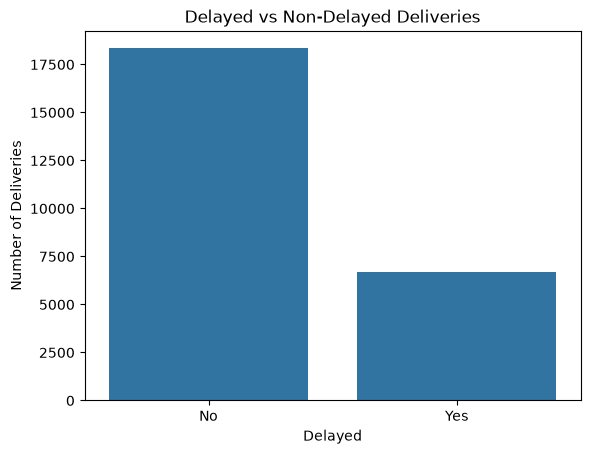

In [25]:
sns.countplot(data=df_model, x='Delayed')

plt.title("Delayed vs Non-Delayed Deliveries")
plt.xlabel("Delayed")
plt.ylabel("Number of Deliveries")
plt.show()

# Visualizing Delayed and Non Delayed Deliveries

## 12. Basic Numerical Analysis

Key numerical variables are analyzed to understand the operational characteristics of the delivery network.

The analysis focuses on:

- Delivery distance
- Package weight
- Delivery cost

Descriptive statistics provide an initial understanding of the range and distribution of these variables.

In [ ]:
# Basic numerical Analysis


# For Distance

print(df_model['Distance_km'].describe())

count    25000.000000
mean       150.390436
std         86.409745
min          3.600000
25%         75.900000
50%        151.000000
75%        224.900000
max        297.100000
Name: Distance_km, dtype: float64


In [27]:
# For Package Weight

print(df_model['Package_weight_kg'].describe())

count    25000.000000
mean        25.145898
std         14.368663
min          0.670000
25%         12.680000
50%         25.145000
75%         37.660000
max         49.520000
Name: Package_weight_kg, dtype: float64


In [28]:
# For Delivery Cost

print(df_model['Delivery_cost'].describe())

count    25000.000000
mean       864.944579
std        435.712593
min         95.667400
25%        490.800000
50%        867.535000
75%       1237.910000
max       1632.720600
Name: Delivery_cost, dtype: float64


# 13. Exploratory Data Analysis

Exploratory Data Analysis is performed to identify patterns and relationships between delivery delays and operational factors.

The analysis investigates delay rates across:

- Delivery Partners
- Vehicle Types
- Delivery Modes
- Weather Conditions
- Regions
- Distance
- Package Weight
- Delivery Cost

These findings help identify potential operational factors that may contribute to delivery delays.

### 13.1 Delay Rate by Delivery Partner

Delivery delay rates are compared across delivery partners to identify partners with relatively higher or lower delay performance.

This analysis can help logistics managers identify areas where partner performance may require further investigation.

In [ ]:
# Delay by delivery partener

partner_delay = pd.crosstab(
    df_model['Delivery_Partner'],
    df_model['Delayed'],
    normalize='index'
) * 100

print(partner_delay)

Delayed                  No        Yes
Delivery_Partner                      
Amazon Logistics  72.777573  27.222427
Blue Dart         73.052180  26.947820
Delhivery         75.197416  24.802584
Dhl               73.661670  26.338330
Ecom Express      73.365173  26.634827
Ekart             72.581221  27.418779
Fedex             74.840312  25.159688
Shadowfax         72.697368  27.302632
Xpressbees        71.726822  28.273178


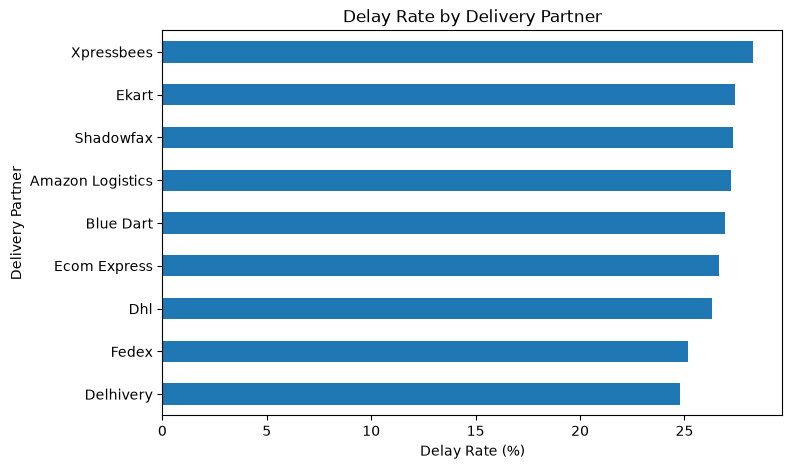

In [30]:
# Visualizing it

partner_delay['Yes'].sort_values().plot(
    kind='barh',
    figsize=(8,5)
)

plt.title("Delay Rate by Delivery Partner")
plt.xlabel("Delay Rate (%)")
plt.ylabel("Delivery Partner")
plt.show()

### 13.2 Delay Rate by Vehicle Type

Delay rates are compared across vehicle types to understand whether the type of vehicle is associated with different delivery outcomes.

In [ ]:
# Delayed by Vehicle

vehicle_delay = pd.crosstab(
    df_model['Vehicle_Type'],
    df_model['Delayed'],
    normalize='index'
) * 100

print(vehicle_delay)

Delayed              No        Yes
Vehicle_Type                      
Bike          72.956731  27.043269
Ev Bike       73.565671  26.434329
Ev Van        73.372206  26.627794
Scooter       73.862003  26.137997
Truck         72.955368  27.044632
Van           73.226654  26.773346


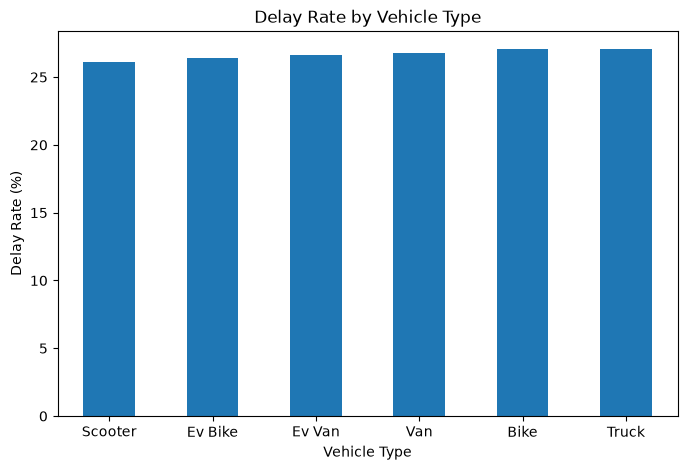

In [32]:
# Visualizing it

vehicle_delay['Yes'].sort_values().plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Delay Rate by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)
plt.show()

### 13.3 Delay Rate by Delivery Mode

Different delivery modes are compared based on their delay rates.

This helps identify delivery modes that may require operational improvements or additional monitoring.

In [ ]:
# Delayed by Delivery Mode

mode_delay = pd.crosstab(
    df_model['Delivery_Mode'],
    df_model['Delayed'],
    normalize='index'
) * 100

print(mode_delay)

Delayed                No        Yes
Delivery_Mode                       
Express         26.215306  73.784694
Same Day        67.462972  32.537028
Standard       100.000000   0.000000
Two Day         99.571565   0.428435


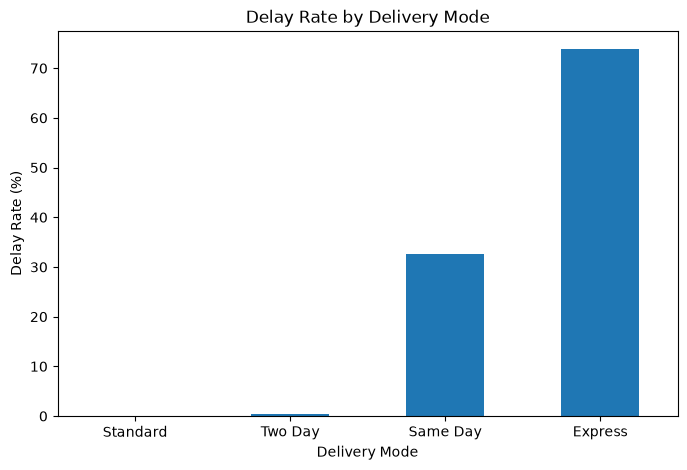

In [34]:
# Visualizing it

mode_delay['Yes'].sort_values().plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Delay Rate by Delivery Mode")
plt.xlabel("Delivery Mode")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)
plt.show()

### 13.4 Delay Rate by Weather Condition

Weather conditions are analyzed to understand their relationship with delivery delays.

This can provide useful operational information for planning deliveries under different weather conditions.

In [ ]:
# Delay by Weather

weather_delay = pd.crosstab(
    df_model['Weather_Condition'],
    df_model['Delayed'],
    normalize='index'
) * 100

print(weather_delay)

Delayed                   No        Yes
Weather_Condition                      
Clear              82.565470  17.434530
Cold               83.982684  16.017316
Foggy              69.684759  30.315241
Hot                82.881356  17.118644
Rainy              62.646847  37.353153
Stormy             58.551691  41.448309


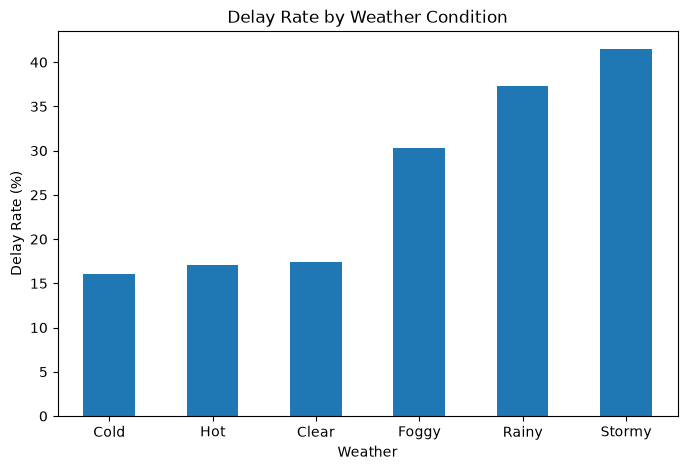

In [36]:
# Visualizing it

weather_delay['Yes'].sort_values().plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Delay Rate by Weather Condition")
plt.xlabel("Weather")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)
plt.show()

### 13.5 Delay Rate by Region

Regional delay rates are compared to identify geographic areas with relatively higher delivery-delay levels.

These patterns can support region-specific logistics planning.

In [ ]:
# Delay by Region

region_delay = pd.crosstab(
    df_model['Region'],
    df_model['Delayed'],
    normalize='index'
) * 100

print(region_delay)

Delayed         No        Yes
Region                       
Central  72.747036  27.252964
East     74.202074  25.797926
North    73.428976  26.571024
South    73.216797  26.783203
West     73.052012  26.947988


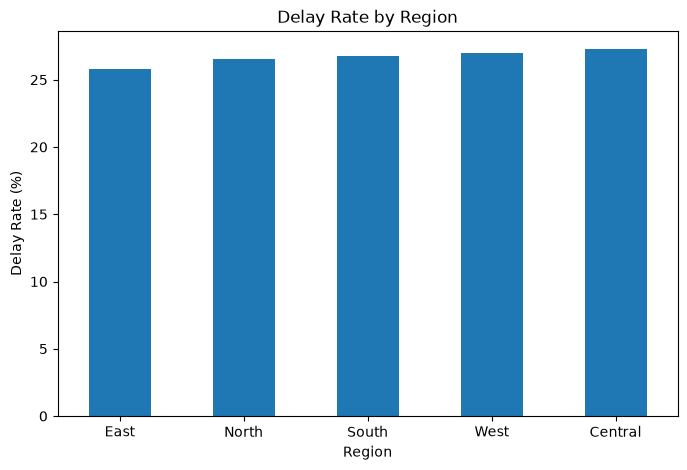

In [38]:
# Visualizing it

region_delay['Yes'].sort_values().plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Delay Rate by Region")
plt.xlabel("Region")
plt.ylabel("Delay Rate (%)")
plt.xticks(rotation=0)
plt.show()

## 14. Distance and Delivery Delay Analysis

Delivery distance is analyzed to determine whether longer delivery routes are associated with a higher likelihood of delay.

The analysis compares the distribution and average distance of delayed and non-delayed deliveries.

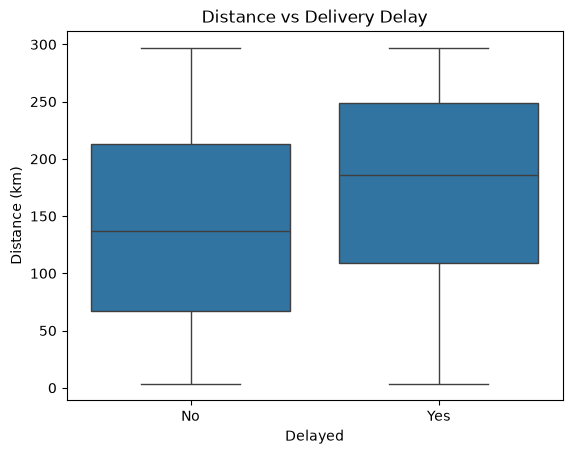

In [ ]:
# Distance Analysis

sns.boxplot(
    data=df_model,
    x='Delayed',
    y='Distance_km'
)

plt.title("Distance vs Delivery Delay")
plt.xlabel("Delayed")
plt.ylabel("Distance (km)")
plt.show()

In [40]:
# Calculating Average 

distance_delay = df_model.groupby('Delayed')['Distance_km'].mean()

print(distance_delay)

Delayed
No     141.302826
Yes    175.369441
Name: Distance_km, dtype: float64


## 15. Package Weight Analysis

Package weight is analyzed to determine whether heavier packages show different delivery patterns compared with lighter packages.

The distribution of package weight is compared between delayed and non-delayed deliveries.

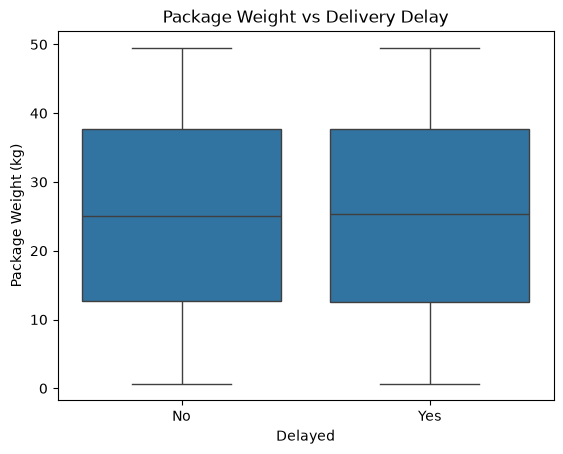

In [ ]:
# Package weight Analysis

sns.boxplot(
    data=df_model,
    x='Delayed',
    y='Package_weight_kg'
)

plt.title("Package Weight vs Delivery Delay")
plt.xlabel("Delayed")
plt.ylabel("Package Weight (kg)")
plt.show()

## 16. Delivery Cost Analysis

Delivery costs are analyzed from an operational perspective.

The analysis examines average delivery cost across vehicle types to understand differences in transportation expenses.

In [ ]:
# Delivery Cost Analysis

# Average cost by Vehicle 

vehicle_cost = df_model.groupby('Vehicle_Type')['Delivery_cost'].mean()

print(vehicle_cost.sort_values())

Vehicle_Type
Van        857.658050
Scooter    862.914003
Truck      864.768182
Ev Van     866.181463
Bike       868.917038
Ev Bike    869.235484
Name: Delivery_cost, dtype: float64


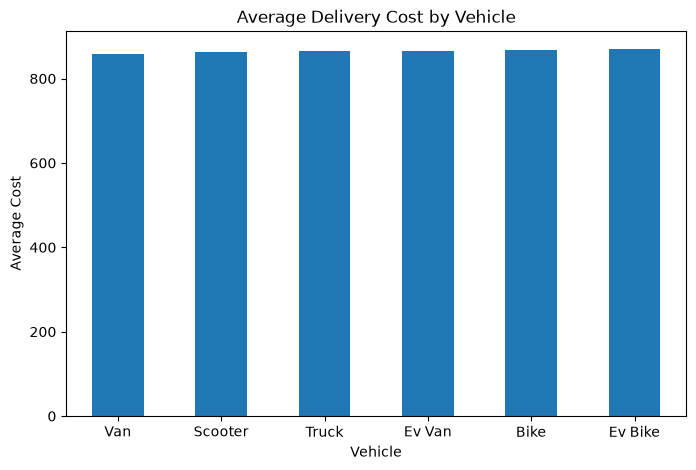

In [43]:
# Visualizing it

vehicle_cost.sort_values().plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Average Delivery Cost by Vehicle")
plt.xlabel("Vehicle")
plt.ylabel("Average Cost")
plt.xticks(rotation=0)
plt.show()

## 17. Cost Efficiency Analysis

Two operational efficiency measures are created:

### Cost per Kilometer

Measures the delivery cost relative to the distance travelled.

### Cost per Kilogram

Measures the delivery cost relative to package weight.

These metrics help compare the cost efficiency of different vehicle types and delivery operations.

In [ ]:
# Cost per Kilometer

# Creating

df_model['Cost_per_km'] = (
    df_model['Delivery_cost'] /
    df_model['Distance_km']
)

In [45]:
# Checking

print(df_model['Cost_per_km'].describe())

count    25000.000000
mean         7.041301
std          5.004036
min          5.002579
25%          5.420741
50%          5.744712
75%          6.494886
max         73.491667
Name: Cost_per_km, dtype: float64


In [46]:
# Average by Vehicle

cost_efficiency = df_model.groupby('Vehicle_Type').agg(
    Average_Cost=('Delivery_cost', 'mean'),
    Average_Distance=('Distance_km', 'mean'),
    Cost_Per_Km=('Cost_per_km', 'mean'),
    Delay_Rate=('Delayed', lambda x: (x == 'Yes').mean() * 100)
)

print(cost_efficiency.sort_values('Cost_Per_Km'))

# This is one of our IMPORTANT TABLE

              Average_Cost  Average_Distance  Cost_Per_Km  Delay_Rate
Vehicle_Type                                                         
Scooter         862.914003        150.160541     6.984862   26.137997
Bike            868.917038        151.423462     7.012126   27.043269
Truck           864.768182        150.265549     7.046139   27.044632
Van             857.658050        148.774254     7.047268   26.773346
Ev Van          866.181463        150.679057     7.067330   26.627794
Ev Bike         869.235484        151.044500     7.089850   26.434329


In [ ]:
# Cost per Kilogram

df_model['Cost_per_kg'] = (
    df_model['Delivery_cost'] /
    df_model['Package_weight_kg']
)

In [ ]:
# Analysing

cost_per_kg = df_model.groupby('Vehicle_Type')['Cost_per_kg'].mean()

print(cost_per_kg.sort_values())

Vehicle_Type
Van        76.118510
Truck      79.673991
Ev Bike    81.380520
Scooter    82.148942
Ev Van     84.474182
Bike       86.722620
Name: Cost_per_kg, dtype: float64


## 18. Correlation Analysis

Correlation analysis is performed on numerical variables to understand the strength and direction of relationships between operational variables.

A correlation heatmap is used to provide a visual overview of these relationships.

Correlation is used as an exploratory technique and does not by itself imply causation.

In [ ]:
# Correction Analysis

# Numerical Variables

numeric_columns = [
    'Distance_km',
    'Package_weight_kg',
    'Delivery_cost',
    'Cost_per_km',
    'Cost_per_kg'
]

correlation = df_model[numeric_columns].corr()

print(correlation)

                   Distance_km  Package_weight_kg  Delivery_cost  Cost_per_km  \
Distance_km           1.000000           0.002311       0.990772    -0.448679   
Package_weight_kg     0.002311           1.000000       0.099479     0.143500   
Delivery_cost         0.990772           0.099479       1.000000    -0.416199   
Cost_per_km          -0.448679           0.143500      -0.416199     1.000000   
Cost_per_kg           0.229582          -0.454463       0.185501    -0.129161   

                   Cost_per_kg  
Distance_km           0.229582  
Package_weight_kg    -0.454463  
Delivery_cost         0.185501  
Cost_per_km          -0.129161  
Cost_per_kg           1.000000  


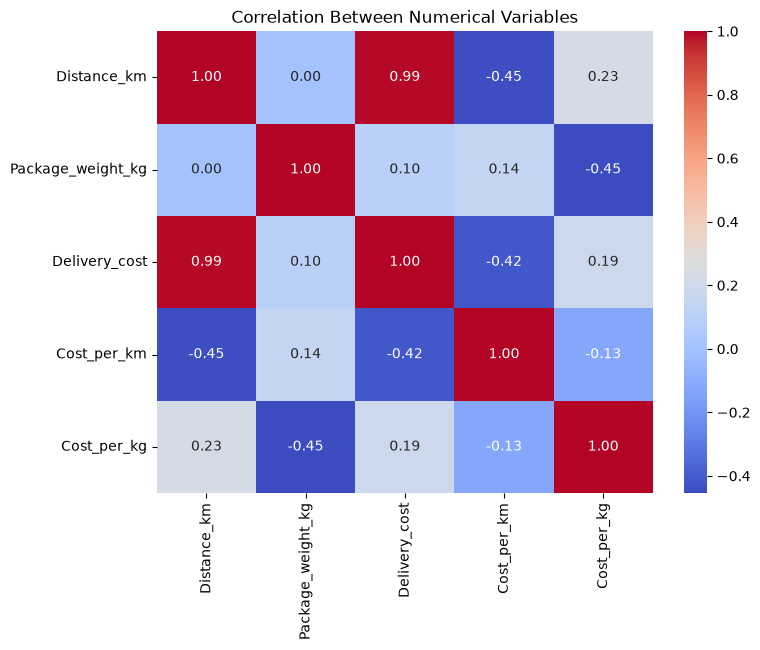

In [50]:
# Heatmap

plt.figure(figsize=(8,6))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title("Correlation Between Numerical Variables")
plt.show()

# 19. Machine Learning — Delivery Delay Prediction

After completing the exploratory analysis, machine learning is introduced to predict delivery delays.

The objective is to estimate the probability that a delivery will be delayed based on information that can reasonably be known before or during the delivery planning process.

### 19.1 Convert the Target Variable into Numerical Form

Machine learning algorithms require a numerical target representation.

The `Delayed` variable is converted into:

- **0 → No delay**
- **1 → Delay**

The resulting `Delayed_Target` variable is used as the machine learning target.

In [ ]:
# Prepare Data for MACHINE LEARNING

# Converting    No-0   and    Yes-1

df_model['Delayed_Target'] = (
    df_model['Delayed']
    .map({'No': 0, 'Yes': 1})
)

In [52]:
# Checking 

print(df_model[['Delayed', 'Delayed_Target']].head())

  Delayed  Delayed_Target
0      No               0
1      No               0
2      No               0
3      No               0
4      No               0


## 20. Feature Selection

The initial model uses operational features that can reasonably be available before delivery.

### Selected Features

- Delivery Partner
- Package Type
- Vehicle Type
- Delivery Mode
- Region
- Weather Condition
- Distance
- Package Weight

These features combine categorical and numerical information to provide the model with operational context for predicting delivery delays.

In [ ]:
# Select ML features

# For the initial model, we used features that can reasonably be known before delivery

features = [
    'Delivery_Partner',
    'Package_Type',
    'Vehicle_Type',
    'Delivery_Mode',
    'Region',
    'Weather_Condition',
    'Distance_km',
    'Package_weight_kg'
]

In [54]:
# Target

X = df_model[features]
y = df_model['Delayed_Target']

## 21. Train-Test Split

The dataset is divided into training and testing sets.

A **stratified split** is used so that the proportion of delayed and non-delayed deliveries is maintained across both datasets.

- **Training data** → Used to train the models
- **Testing data** → Used to evaluate model performance on unseen data

In [ ]:
# Train / Test split

# We'll use a stratified split because the target isn't perfectly balanced.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [56]:
# Checking 

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (20000, 8)
Testing data: (5000, 8)


## 22. Data Preprocessing

The dataset contains both categorical and numerical variables, so different preprocessing steps are required.

### Categorical Features

Categorical variables are converted into numerical representations using one-hot encoding.

### Numerical Features

Numerical variables are standardized to ensure that they are on a comparable scale.

A `ColumnTransformer` is used to apply the appropriate preprocessing to each feature type.

In [ ]:
# Preprocessing

# Our data contains both CATEGORICAL and NUMERICAL
# To standardize the data we need to convert CATEGORICAL Data into Numerical

# Converting CATEGORICAL variables into numbers

categorical_features = [
    'Delivery_Partner',
    'Package_Type',
    'Vehicle_Type',
    'Delivery_Mode',
    'Region',
    'Weather_Condition'
]

numerical_features = [
    'Distance_km',
    'Package_weight_kg'
]

In [58]:
# Creating Preprocessing 

preprocessor = ColumnTransformer(
    transformers=[
        (
            'categorical',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        ),
        (
            'numerical',
            StandardScaler(),
            numerical_features
        )
    ]
)

## 23. Model 1 — Logistic Regression

Logistic Regression is used as the first baseline classification model.

It provides a simple and interpretable approach for predicting whether a delivery is likely to be delayed.

The model is implemented inside a pipeline so that preprocessing and model training are handled consistently.

In [ ]:
# MODEL 1 : Logistics Regression

logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(
            max_iter=1000,
            class_weight='balanced'
        ))
    ]
)

In [60]:
# TRAIN

logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Delivery_Partner','Package_Type','Vehicle_Type',...,'Weather_Condition', 'Distance_km','Package_weight_kg']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'`

In [61]:
# PREDICT

y_pred_lr = logistic_model.predict(X_test)

In [62]:
# PROBABILITY

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

### 23.1 Logistic Regression Evaluation

The Logistic Regression model is evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Classification report

In [ ]:
# Evaluate Logistic Regression

print("Logistic Regression")
print("-------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_lr)
)

print(
    "Precision:",
    precision_score(y_test, y_pred_lr)
)

print(
    "Recall:",
    recall_score(y_test, y_pred_lr)
)

print(
    "F1 Score:",
    f1_score(y_test, y_pred_lr)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob_lr)
)

Logistic Regression
-------------------
Accuracy: 0.886
Precision: 0.7210648148148148
Recall: 0.9340329835082459
F1 Score: 0.813847158719791
ROC-AUC: 0.9611998419775383


In [64]:
# Detailed Report 

print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

              precision    recall  f1-score   support

           0       0.97      0.87      0.92      3666
           1       0.72      0.93      0.81      1334

    accuracy                           0.89      5000
   macro avg       0.85      0.90      0.87      5000
weighted avg       0.91      0.89      0.89      5000



### 23.2 Confusion Matrix

A confusion matrix is used to examine:

- Correctly predicted delays
- Correctly predicted non-delays
- Incorrectly predicted delays
- Missed delays

This is particularly important because missing an actual delayed delivery can have operational consequences.

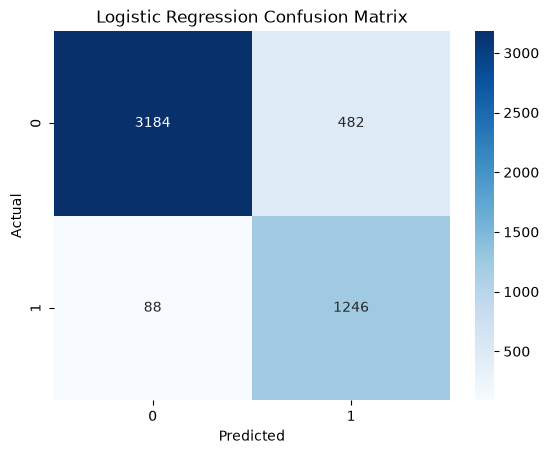

In [ ]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 24. Model 2 — Decision Tree

A Decision Tree classifier is trained as a second machine learning approach.

Decision Trees can capture non-linear relationships between operational features and delivery delays while providing a relatively interpretable model structure.

In [ ]:
# MODEL 2 : Decision Tree

decision_tree = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            DecisionTreeClassifier(
                max_depth=8,
                random_state=42,
                class_weight='balanced'
            )
        )
    ]
)

In [67]:
# TRAIN

decision_tree.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Delivery_Partner','Package_Type','Vehicle_Type',...,'Weather_Condition', 'Distance_km','Package_weight_kg']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'`

In [68]:
# PREDICT

y_pred_dt = decision_tree.predict(X_test)
y_prob_dt = decision_tree.predict_proba(X_test)[:, 1]

In [69]:
# EVALUATE

print("Decision Tree")
print("-------------")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

Decision Tree
-------------
Accuracy: 0.8826
Precision: 0.7048820625342841
Recall: 0.9632683658170914
F1: 0.8140639847956921
ROC-AUC: 0.9617698311237179


## 25. Model 3 — Random Forest

Random Forest is used as the third classification model.

It combines multiple decision trees to improve predictive performance and reduce the risk of relying on a single decision tree.

The model is evaluated using the same performance metrics as the previous models.

In [ ]:
# MODEL 3 : Random Forest

random_forest = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        (
            'model',
            RandomForestClassifier(
                n_estimators=200,
                max_depth=12,
                random_state=42,
                class_weight='balanced',
                n_jobs=-1
            )
        )
    ]
)

In [71]:
# TRAIN

random_forest.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Delivery_Partner','Package_Type','Vehicle_Type',...,'Weather_Condition', 'Distance_km','Package_weight_kg']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'`

In [72]:
# PREDICT

y_pred_rf = random_forest.predict(X_test)

y_prob_rf = random_forest.predict_proba(X_test)[:, 1]

In [73]:
# EVALUATE

print("Random Forest")
print("-------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Random Forest
-------------
Accuracy: 0.8876
Precision: 0.7142064372918979
Recall: 0.9647676161919041
F1: 0.8207908163265306
ROC-AUC: 0.9652015236244399


# 26. Model Comparison

The performance of Logistic Regression, Decision Tree, and Random Forest is compared using common classification metrics.

The comparison helps identify the model that provides the most suitable balance between correctly identifying delayed deliveries and avoiding incorrect predictions.

For this business problem, **F1-score is given particular importance** because both precision and recall matter when identifying potentially delayed deliveries.

In [ ]:
# Comparing all Models

results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],
    
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],
    
    'F1_Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ],
    
    'ROC_AUC': [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

print(results.sort_values('F1_Score', ascending=False))

                 Model  Accuracy  Precision    Recall  F1_Score   ROC_AUC
2        Random Forest    0.8876   0.714206  0.964768  0.820791  0.965202
1        Decision Tree    0.8826   0.704882  0.963268  0.814064  0.961770
0  Logistic Regression    0.8860   0.721065  0.934033  0.813847  0.961200


### Why F1-Score?

Accuracy alone may not be sufficient for this problem because the business objective is not simply to maximize the number of correct predictions.

The model should identify delayed deliveries effectively while avoiding too many false alerts.

The **F1-score** combines:

- **Precision** — How many predicted delays were actually delayed.
- **Recall** — How many actual delays were successfully identified.

Therefore, F1-score provides a useful balance between precision and recall for this delivery-risk prediction problem.

## 27. Cross-Validation

Cross-validation is used to evaluate whether the model performs consistently across different subsets of the dataset.

A **Stratified K-Fold** approach is used so that the proportion of delayed and non-delayed deliveries is maintained in each fold.

F1-score is used as the evaluation metric because identifying delayed deliveries is the primary business objective.

In [ ]:
# Cross Validation

# We should check whether our model performs consistently.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [77]:
# Random Forest

cv_scores = cross_val_score(
    random_forest,
    X,
    y,
    cv=cv,
    scoring='f1'
)

print("F1 scores:", cv_scores)
print("Mean F1:", cv_scores.mean())
print("Std F1:", cv_scores.std())

# This gives us a more reliable estimate than relying on only one train/test split.

F1 scores: [0.81255887 0.81563891 0.82394366 0.82101167 0.80920422]
Mean F1: 0.8164714659946994
Std F1: 0.0053900212138108874


## 28. Hyperparameter Tuning

The Random Forest model is further optimized using `GridSearchCV`.

Different combinations of Random Forest parameters are tested, including:

- Number of trees
- Maximum tree depth
- Minimum samples required for splitting
- Minimum samples required at a leaf node

Five-fold cross-validation and F1-score are used to identify the best-performing parameter combination.

In [ ]:
# Hyperparameter tuning

# Now we'll try to improve Random Forest.

param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [8, 12, 16],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

In [79]:
# Creating Grid Search

grid_search = GridSearchCV(
    random_forest,
    param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

In [80]:
# TRAIN

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [8, 12, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sph

In [81]:
# Best Parameter

print(grid_search.best_params_)

{'model__max_depth': 16, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}


In [82]:
# Best CV Score

print(grid_search.best_params_)

{'model__max_depth': 16, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}


In [83]:
# Best Model

print(grid_search.best_params_)

{'model__max_depth': 16, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}


In [84]:
# Creating the beat model from GridSearchCV

best_model = grid_search.best_estimator_

# 29. Final Model Evaluation

The best Random Forest model identified through hyperparameter tuning is evaluated on the unseen test dataset.

The final evaluation includes:

- Accuracy
- Precision
- Recall
- F1-score
- Classification Report
- Confusion Matrix

In [ ]:
# Evaluate the final Model

final_predictions = best_model.predict(X_test)

final_probabilities = (
    best_model.predict_proba(X_test)[:, 1]
)

In [86]:
# Metrics 

print("Final Model Performance")
print("-----------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, final_predictions)
)

print(
    "Precision:",
    precision_score(y_test, final_predictions)
)

print(
    "Recall:",
    recall_score(y_test, final_predictions)
)

print(
    "F1 Score:",
    f1_score(y_test, final_predictions)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, final_probabilities)
)

Final Model Performance
-----------------------
Accuracy: 0.889
Precision: 0.7237219988512349
Recall: 0.9445277361319341
F1 Score: 0.8195121951219512
ROC-AUC: 0.9651260703527125


In [87]:
# Classification Report

print(
    classification_report(
        y_test,
        final_predictions
    )
)

              precision    recall  f1-score   support

           0       0.98      0.87      0.92      3666
           1       0.72      0.94      0.82      1334

    accuracy                           0.89      5000
   macro avg       0.85      0.91      0.87      5000
weighted avg       0.91      0.89      0.89      5000



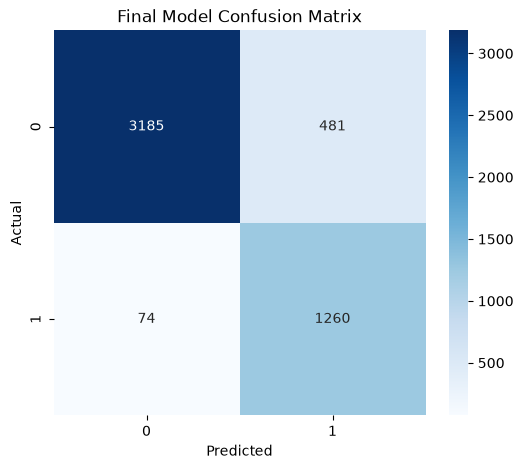

In [88]:
# Part 28 : Final Confusion Matrix

cm = confusion_matrix(
    y_test,
    final_predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Final Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## 30. Feature Importance

Feature importance is extracted from the optimized Random Forest model to understand which operational variables contribute most strongly to the model's predictions.

This step improves model interpretability and helps translate machine learning results into business insights.

The most important predictive features are visualized and ranked.

In [ ]:
# Feature Impotance

# This is important for explaining the model.
#First obtain the transformed feature names:

feature_names = (
    best_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

In [90]:
# Getting Importance

importance = (
    best_model
    .named_steps['model']
    .feature_importances_
)

In [91]:
# Creating Table

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

In [92]:
# Sorting

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
)

In [93]:
# Displaying

print(feature_importance.head(20))

                                  Feature  Importance
24     categorical__Delivery_Mode_Express    0.300411
27     categorical__Delivery_Mode_Two Day    0.140716
26    categorical__Delivery_Mode_Standard    0.134869
39                 numerical__Distance_km    0.108960
25    categorical__Delivery_Mode_Same Day    0.084889
40           numerical__Package_weight_kg    0.038269
38  categorical__Weather_Condition_Stormy    0.023354
34    categorical__Weather_Condition_Cold    0.015351
33   categorical__Weather_Condition_Clear    0.012777
36     categorical__Weather_Condition_Hot    0.012729
37   categorical__Weather_Condition_Rainy    0.012585
35   categorical__Weather_Condition_Foggy    0.005889
30              categorical__Region_North    0.004685
29               categorical__Region_East    0.004580
28            categorical__Region_Central    0.004490
32               categorical__Region_West    0.004472
21      categorical__Vehicle_Type_Scooter    0.004411
31              categorical_

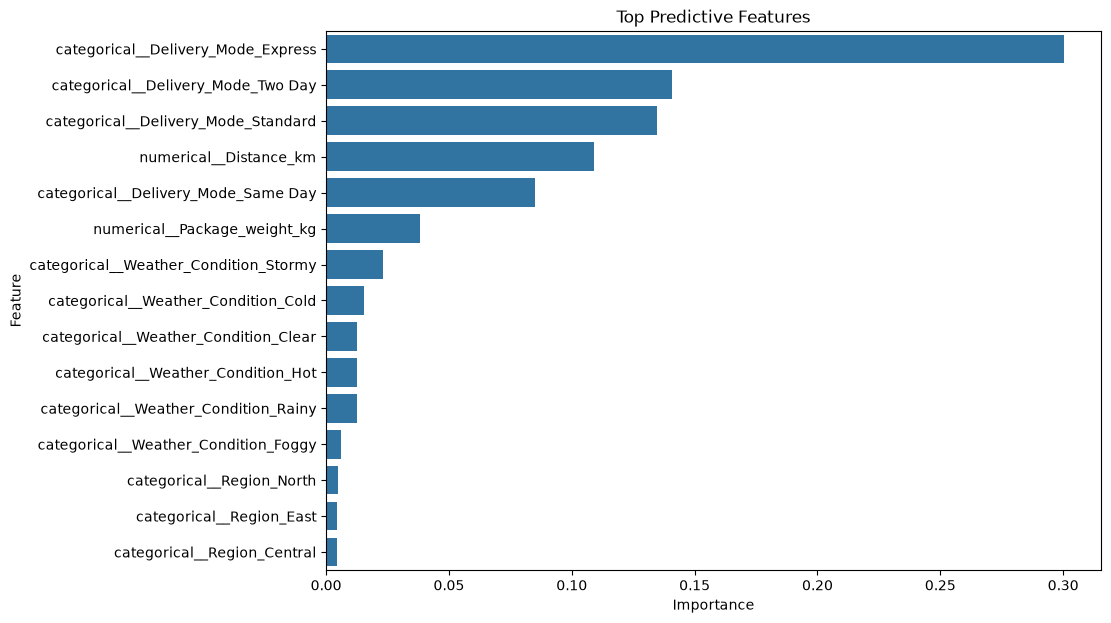

In [94]:
# Visualizing it

top_features = feature_importance.head(15)

plt.figure(figsize=(10,7))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title("Top Predictive Features")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

# 31. AI-Powered Delivery Risk Prediction

The optimized Random Forest model is now used to generate predictions for the complete dataset.

For every delivery, the system generates:

- Delay probability
- Delay risk percentage
- Predicted delay status

This transforms the machine learning model from a prediction experiment into an operational risk-scoring system.

In [ ]:
# Predict risk for every delivery


# Now comes the AI-powered part.

# Train the final model on the entire dataset

best_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Delivery_Partner','Package_Type','Vehicle_Type',...,'Weather_Condition', 'Distance_km','Package_weight_kg']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'`

In [96]:
# Predicting Every Delivery

df_model['Delay_Probability'] = (
    best_model.predict_proba(X)[:, 1]
)

In [97]:
# Converting Probability into percentage

df_model['Delay_Risk_Percentage'] = (
    df_model['Delay_Probability'] * 100
)

In [98]:
# Prediction

df_model['Predicted_Delay'] = (
    best_model.predict(X)
)

In [99]:
# Convert

df_model['Predicted_Delay'] = (
    df_model['Predicted_Delay']
    .map({0: 'No', 1: 'Yes'})
)

## 32. Delivery Risk Categorization

The predicted delay probability is converted into three operational risk categories.

| Delay Probability | Risk Category |
|---|---|
| 70% or above | High Risk |
| 40%–69.99% | Medium Risk |
| Below 40% | Low Risk |

These categories make the model output easier for business and operations teams to understand and act upon.

In [ ]:
# Create Risk Categories

# This is useful for Business Teanm

def risk_category(probability):

    if probability >= 0.70:
        return 'High Risk'
    
    elif probability >= 0.40:
        return 'Medium Risk'
    
    else:
        return 'Low Risk'

In [101]:
# Applying

df_model['Risk_Category'] = (
    df_model['Delay_Probability']
    .apply(risk_category)
)


In [102]:
# Checking 

print(
    df_model['Risk_Category']
    .value_counts()
)

Risk_Category
Low Risk       15997
High Risk       6646
Medium Risk     2357
Name: count, dtype: int64


## 33. Identify High-Risk Deliveries

Deliveries classified as **High Risk** are extracted and sorted according to their predicted delay probability.

This creates a prioritized list of deliveries that may require proactive operational attention.

Potential business actions could include:

- Monitoring the delivery closely
- Reviewing the assigned vehicle or delivery mode
- Checking weather or regional conditions
- Prioritizing operational intervention
- Communicating potential delays to relevant teams

In [ ]:
# Find high-risk deliveries 

high_risk_deliveries = df_model[
    df_model['Risk_Category'] == 'High Risk'
]

In [104]:
# Sort 

high_risk_deliveries = high_risk_deliveries.sort_values(
    'Delay_Probability',
    ascending=False
)

In [105]:
# Viewing

print(
    high_risk_deliveries.head(20)
)

# This gives the operations team a list of deliveries that deserve attention.

       Delivery_Partner      Package_Type Vehicle_Type Delivery_Mode   Region  \
1315              Ekart         Groceries          Van       Express    North   
21811         Delhivery         Groceries        Truck       Express     West   
8494              Ekart         Documents          Van       Express    North   
23092  Amazon Logistics          Pharmacy         Bike       Express     East   
21198             Ekart  Automobile Parts      Ev Bike       Express  Central   
12411        Xpressbees         Groceries         Bike       Express    North   
11752             Fedex         Furniture        Truck       Express     East   
2671   Amazon Logistics     Fragile Items          Van       Express     East   
3789              Ekart         Cosmetics       Ev Van       Express  Central   
3608          Shadowfax         Groceries          Van       Express     West   
11144        Xpressbees         Documents          Van       Express     East   
6363              Ekart     

# 34. Logistics Optimization Analysis

The project now moves beyond prediction toward operational decision-making.

The objective is to evaluate logistics performance across:

- Vehicle types
- Delivery partners
- Regions
- Delivery modes
- Weather conditions

These analyses help identify areas where operational efficiency and delivery reliability can potentially be improved.

## 35. Vehicle Performance Analysis

Vehicle types are evaluated using operational metrics including:

- Total deliveries
- Average delivery distance
- Average package weight
- Average delivery cost
- Average delivery rating
- Delay rate
- Cost per kilometer

This provides a comparative view of vehicle performance and cost efficiency.

In [ ]:
# Logistics Optimization Analysis


# Now we move from prediction to decision-making.

# Create a vehicle performance table:

vehicle_analysis = df.groupby('Vehicle_Type').agg(
    Total_Deliveries=('Vehicle_Type', 'count'),
    Average_Distance=('Distance_km', 'mean'),
    Average_Weight=('Package_weight_kg', 'mean'),
    Average_Cost=('Delivery_cost', 'mean'),
    Average_Rating=('Delivery_rating', 'mean')
)

In [107]:
# Delay Rate

vehicle_delay_rate = (
    df.groupby('Vehicle_Type')['Delayed']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

vehicle_analysis['Delay_Rate'] = vehicle_delay_rate

In [108]:
# Cost per Km

vehicle_analysis['Cost_Per_Km'] = (
    df.groupby('Vehicle_Type')
    .apply(
        lambda x: (
            x['Delivery_cost'] / x['Distance_km']
        ).mean(),
        include_groups=False
    )
)

In [109]:
# Displaying

print(
    vehicle_analysis.sort_values('Delay_Rate')
)

              Total_Deliveries  Average_Distance  Average_Weight  \
Vehicle_Type                                                       
Scooter                   4174        150.160541       24.633819   
Ev Bike                   4218        151.044500       25.427750   
Ev Van                    4116        150.679057       25.018737   
Van                       4187        148.774254       25.368094   
Bike                      4160        151.423462       25.008192   
Truck                     4145        150.265549       25.414770   

              Average_Cost  Average_Rating  Delay_Rate  Cost_Per_Km  
Vehicle_Type                                                         
Scooter         862.914003        3.677048   26.137997     6.984862  
Ev Bike         869.235484        3.667852   26.434329     7.089850  
Ev Van          866.181463        3.678086   26.627794     7.067330  
Van             857.658050        3.660855   26.773346     7.047268  
Bike            868.917038        3

## 36. Delivery Partner Performance

Delivery partners are compared based on their delivery volume and delay performance.

The analysis calculates:

- Total deliveries
- Delay rate

This can help identify partners with relatively stronger or weaker delivery reliability.

In [ ]:
# Partner Performance

partner_analysis = df.groupby('Delivery_Partner').agg(
    Total_Deliveries=('Delivery_Partner', 'count'),
    Average_Cost=('Delivery_cost', 'mean'),
    Average_Rating=('Delivery_rating', 'mean'),
    Average_Distance=('Distance_km', 'mean')
)

In [111]:
# Delay Rate 

partner_analysis['Delay_Rate'] = (
    df.groupby('Delivery_Partner')['Delayed']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

In [112]:
# Sorting

partner_analysis = partner_analysis.sort_values(
    'Delay_Rate'
)

print(partner_analysis)

                  Total_Deliveries  Average_Cost  Average_Rating  \
Delivery_Partner                                                   
Delhivery                     2786    848.109810        3.687724   
Fedex                         2818    857.355640        3.698368   
Dhl                           2802    872.831125        3.685225   
Ecom Express                  2722    868.772186        3.674504   
Blue Dart                     2798    863.021705        3.677627   
Amazon Logistics              2711    868.150131        3.644412   
Shadowfax                     2736    868.340156        3.661550   
Ekart                         2801    869.966720        3.655480   
Xpressbees                    2826    868.165768        3.608988   

                  Average_Distance  Delay_Rate  
Delivery_Partner                                
Delhivery               147.037904   24.802584  
Fedex                   148.778708   25.159688  
Dhl                     152.084404   26.338330  
Ecom E

## 37. Regional Performance Analysis

Delivery performance is analyzed across regions.

The analysis compares delivery volume and delay rates to identify regions that may require additional operational attention.

In [ ]:
# Region Performance

region_analysis = df.groupby('Region').agg(
    Total_Deliveries=('Region', 'count'),
    Average_Cost=('Delivery_cost', 'mean'),
    Average_Distance=('Distance_km', 'mean'),
    Average_Rating=('Delivery_rating', 'mean')
)

In [114]:
# Delay

region_analysis['Delay_Rate'] = (
    df.groupby('Region')['Delayed']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

In [115]:
print(region_analysis)

         Total_Deliveries  Average_Cost  Average_Distance  Average_Rating  \
Region                                                                      
Central              5060    869.950989        151.042569        3.660672   
East                 4919    861.455929        149.857308        3.682252   
North                4949    860.439223        149.562639        3.679935   
South                4977    858.296324        149.169118        3.667671   
West                 5095    874.211232        152.254603        3.640432   

         Delay_Rate  
Region               
Central   27.252964  
East      25.797926  
North     26.571024  
South     26.783203  
West      26.947988  


## 38. Delivery Mode Performance

Different delivery modes are compared based on their delivery volume and delay rate.

This analysis can help operations teams evaluate the reliability of different delivery approaches.

In [ ]:
# Delivery Mode Performance

mode_analysis = df.groupby('Delivery_Mode').agg(
    Total_Deliveries=('Delivery_Mode', 'count'),
    Average_Cost=('Delivery_cost', 'mean'),
    Average_Distance=('Distance_km', 'mean')
)

In [117]:
mode_analysis['Delay_Rate'] = (
    df.groupby('Delivery_Mode')['Delayed']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

In [118]:
print(mode_analysis)

               Total_Deliveries  Average_Cost  Average_Distance  Delay_Rate
Delivery_Mode                                                              
Express                    6233    880.426426        150.954805   73.784694
Same Day                   6279    929.872468        151.161236   32.537028
Standard                   6186    819.335575        148.610734    0.000000
Two Day                    6302    829.710800        150.811203    0.428435


## 39. Weather Impact Analysis

Weather conditions are analyzed from an operational perspective by comparing delivery volume and delay rates.

The results can help identify weather conditions associated with higher delivery-delay rates and support proactive planning.

In [ ]:
# Weather impact 

weather_analysis = df.groupby('Weather_Condition').agg(
    Total_Deliveries=('Weather_Condition', 'count'),
    Average_Distance=('Distance_km', 'mean'),
    Average_Cost=('Delivery_cost', 'mean')
)

In [120]:
weather_analysis['Delay_Rate'] = (
    df.groupby('Weather_Condition')['Delayed']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

In [121]:
print(weather_analysis.sort_values(
    'Delay_Rate',
    ascending=False
))

                   Total_Deliveries  Average_Distance  Average_Cost  \
Weather_Condition                                                     
Stormy                         4198        149.266365    859.247482   
Rainy                          4171        150.980269    867.469355   
Foggy                          4219        150.036312    862.682236   
Clear                          4124        150.483075    865.366973   
Hot                            4130        150.894455    868.231080   
Cold                           4158        150.700457    866.776034   

                   Delay_Rate  
Weather_Condition              
Stormy              41.448309  
Rainy               37.353153  
Foggy               30.315241  
Clear               17.434530  
Hot                 17.118644  
Cold                16.017316  


## 40. High-Risk and High-Cost Deliveries

A focused analysis is performed to identify deliveries that combine:

- High predicted delay risk
- High delivery cost

These deliveries are particularly important from a business perspective because they represent situations where operational risk and financial impact occur together.

In [ ]:
# High- Risk + High-Cost Deliveries

# This is useful for busines perspective

high_risk_high_cost = df_model[
    (df_model['Risk_Category'] == 'High Risk') &
    (
        df_model['Delivery_cost'] >=
        df_model['Delivery_cost'].quantile(0.75)
    )
]

In [123]:
# Sorting

high_risk_high_cost = high_risk_high_cost.sort_values(
    'Delay_Probability',
    ascending=False
)

In [124]:
# Checking


print(high_risk_high_cost.head(20))


# These are deliveries where:

# The predicted delay risk is high AND the delivery cost is relatively high.

# Those can be prioritized by the operations team.

       Delivery_Partner      Package_Type Vehicle_Type Delivery_Mode   Region  \
1315              Ekart         Groceries          Van       Express    North   
21811         Delhivery         Groceries        Truck       Express     West   
12411        Xpressbees         Groceries         Bike       Express    North   
3789              Ekart         Cosmetics       Ev Van       Express  Central   
3608          Shadowfax         Groceries          Van       Express     West   
18108             Ekart  Automobile Parts      Ev Bike       Express    North   
7320          Blue Dart          Pharmacy        Truck       Express  Central   
12880        Xpressbees         Documents      Ev Bike       Express    North   
14170        Xpressbees         Groceries         Bike       Express    South   
9793          Blue Dart       Electronics          Van       Express    North   
13670      Ecom Express          Pharmacy       Ev Van       Express    South   
21582             Ekart     

# 41. Logistics Priority Score

To support operational prioritization, a composite Logistics Priority Score is created.

The score combines three normalized factors:

- **Delay Risk Score — 50%**
- **Delivery Cost Score — 30%**
- **Distance Score — 20%**

### Formula

**Logistics Priority Score =  
0.50 × Risk Score +  
0.30 × Cost Score +  
0.20 × Distance Score**

A higher score indicates a delivery that may deserve greater operational attention based on its predicted risk, cost, and distance.

In [ ]:
# Create a logistics Priority Score

'''We can combine:

delay risk
delivery cost
distance

into a simple operational score.

First normalize'''  


from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_model[
    ['Risk_Score', 'Cost_Score', 'Distance_Score']
] = scaler.fit_transform(
    df_model[
        [
            'Delay_Probability',
            'Delivery_cost',
            'Distance_km'
        ]
    ]
)


In [126]:
# Create Score

df_model['Logistics_Priority_Score'] = (
    0.50 * df_model['Risk_Score'] +
    0.30 * df_model['Cost_Score'] +
    0.20 * df_model['Distance_Score']
)

In [127]:
# Sorting

priority_deliveries = df_model.sort_values(
    'Logistics_Priority_Score',
    ascending=False
)

In [128]:
# Viewing

print(priority_deliveries.head(20))

       Delivery_Partner      Package_Type Vehicle_Type Delivery_Mode   Region  \
6901         Xpressbees          Pharmacy          Van       Express     West   
13725         Delhivery          Pharmacy          Van       Express     West   
356           Blue Dart     Fragile Items      Ev Bike       Express    North   
7326              Ekart  Automobile Parts      Ev Bike       Express  Central   
6525          Delhivery         Groceries         Bike       Express    South   
19154         Blue Dart          Pharmacy      Scooter       Express     West   
23266        Xpressbees         Furniture       Ev Van       Express     West   
10188         Blue Dart         Cosmetics      Scooter       Express     East   
6303          Shadowfax         Cosmetics          Van       Express    South   
704           Blue Dart  Automobile Parts        Truck       Express     West   
11334         Shadowfax  Automobile Parts       Ev Van       Express    South   
23046         Shadowfax     

# 42. Create Final Prediction Dataset

A final structured dataset is created to combine the most important operational and machine learning outputs.

The final dataset contains:

- Delivery information
- Operational characteristics
- Delay status
- Delay probability
- Predicted delay
- Risk category
- Cost efficiency metrics
- Logistics Priority Score

This dataset is designed to serve as the main input for the Power BI dashboard.

In [ ]:
# Creating Final Prediction Dataset

# We want a clean table for Power BI


final_predictions = df_model[
    [
        'Delivery_Partner',
        'Package_Type',
        'Vehicle_Type',
        'Delivery_Mode',
        'Region',
        'Weather_Condition',
        'Distance_km',
        'Package_weight_kg',
        'Delivery_cost',
        'Delayed',
        'Delay_Probability',
        'Delay_Risk_Percentage',
        'Predicted_Delay',
        'Risk_Category',
        'Cost_per_km',
        'Cost_per_kg',
        'Logistics_Priority_Score'
    ]
].copy()

In [130]:
# Checking

print(final_predictions.head())

  Delivery_Partner      Package_Type Vehicle_Type Delivery_Mode   Region  \
0        Delhivery  Automobile Parts         Bike      Same Day     West   
1       Xpressbees         Cosmetics       Ev Van       Express  Central   
2        Shadowfax         Groceries        Truck       Two Day     East   
3              Dhl       Electronics       Ev Van      Same Day     East   
4              Dhl          Clothing          Van       Two Day    North   

  Weather_Condition  Distance_km  Package_weight_kg  Delivery_cost Delayed  \
0             Clear        297.0              46.96      1632.7206      No   
1              Cold         89.6              47.39       640.1700      No   
2             Rainy        273.5              26.89      1448.1700      No   
3              Cold        269.7              12.69      1486.5700      No   
4             Foggy        256.7              37.02      1394.5600      No   

   Delay_Probability  Delay_Risk_Percentage Predicted_Delay Risk_Category 

# 43. Export Project Outputs

The final project outputs are saved in a dedicated `project_outputs` folder.

The exported files include:

- Clean delivery dataset
- Delivery predictions
- High-risk deliveries
- Vehicle analysis
- Partner analysis
- Region analysis
- Delivery-mode analysis
- Weather analysis
- Model comparison results

These files separate the machine learning and analytical outputs from the notebook and make them reusable for reporting and Power BI visualization.

In [ ]:
# Saving Files 

# Creating an output Folder


# import os

# os.makedirs("project_outputs", exist_ok=True)

In [132]:
# Saving Clean Data 

""" df.to_excel(
    "project_outputs/clean_delivery_data.xlsx",
    index=False
)"""

' df.to_excel(\n    "project_outputs/clean_delivery_data.xlsx",\n    index=False\n)'

In [133]:
# Saving Model Predictions 

"""final_predictions.to_excel(
    "project_outputs/delivery_predictions.xlsx",
    index=False
)"""

'final_predictions.to_excel(\n    "project_outputs/delivery_predictions.xlsx",\n    index=False\n)'

In [134]:
# Saving High-risk deliveries

"""high_risk_deliveries.to_excel(
    "project_outputs/high_risk_deliveries.xlsx",
    index=False
)"""

'high_risk_deliveries.to_excel(\n    "project_outputs/high_risk_deliveries.xlsx",\n    index=False\n)'

In [135]:
# Saving Vehicle Analysis

"""vehicle_analysis.to_excel(
    "project_outputs/vehicle_analysis.xlsx"
)"""

'vehicle_analysis.to_excel(\n    "project_outputs/vehicle_analysis.xlsx"\n)'

In [136]:
# Saving Partner Analysis

"""partner_analysis.to_excel(
    "project_outputs/partner_analysis.xlsx"
)"""

'partner_analysis.to_excel(\n    "project_outputs/partner_analysis.xlsx"\n)'

In [137]:
# Save Region Analysis

"""region_analysis.to_excel(
    "project_outputs/region_analysis.xlsx"
)"""

'region_analysis.to_excel(\n    "project_outputs/region_analysis.xlsx"\n)'

In [138]:
# Save Delivery-Mode Analysis

"""mode_analysis.to_excel(
    "project_outputs/delivery_mode_analysis.xlsx"
)"""

'mode_analysis.to_excel(\n    "project_outputs/delivery_mode_analysis.xlsx"\n)'

In [139]:
# Saving Weather Analysis 

"""weather_analysis.to_excel(
    "project_outputs/weather_analysis.xlsx"
)"""

'weather_analysis.to_excel(\n    "project_outputs/weather_analysis.xlsx"\n)'

In [140]:
# Saving Model Results

"""results.to_excel(
    "project_outputs/model_comparison.xlsx",
    index=False
)"""

'results.to_excel(\n    "project_outputs/model_comparison.xlsx",\n    index=False\n)'

# 44. Project Conclusion

This project demonstrates an end-to-end supply chain analytics and machine learning workflow.

### Key Components

**Data Preparation**
- Loaded and inspected delivery data
- Identified missing values and duplicates
- Standardized categorical text
- Created separate analytical and modelling datasets

**Exploratory Analysis**
- Analyzed delivery delays across partners, vehicles, modes, regions, and weather conditions
- Examined distance, package weight, and delivery cost
- Created cost-efficiency metrics
- Investigated numerical relationships using correlation analysis

**Machine Learning**
- Prepared categorical and numerical features
- Compared Logistic Regression, Decision Tree, and Random Forest
- Used cross-validation
- Optimized Random Forest using GridSearchCV
- Evaluated the final model using classification metrics and a confusion matrix

**AI-Powered Risk Prediction**
- Generated delay probabilities for deliveries
- Classified deliveries into Low, Medium, and High Risk
- Identified high-risk deliveries
- Extracted important predictive features

**Logistics Optimization**
- Compared vehicle performance
- Evaluated delivery partner performance
- Analyzed regional and delivery-mode performance
- Studied weather-related delivery patterns
- Identified high-risk and high-cost deliveries
- Created a Logistics Priority Score

**Business Intelligence**
The final analytical and prediction datasets are exported for use in Power BI, enabling the creation of an interactive supply chain and logistics performance dashboard.

### Business Value

The platform transforms raw delivery data into actionable information that can help logistics teams monitor delivery performance, identify potential delays earlier, prioritize operational attention, compare logistics performance, and support data-driven decision-making.